## Dependicies

In [ ]:
# 1. Core Data & Math
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 2. Visualization (helpful for your final report)
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Validation & Preprocessing
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder

# 4. Fast & Strong Sklearn Models
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier
)

# 5. Evaluation Metrics
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All dependencies imported successfully!")

All dependencies imported successfully!


In [ ]:
train = pd.read_csv('train (1).csv')
test = pd.read_csv('test.csv')

print("Train columns:", list(train.columns))
print("Test columns: ", list(test.columns))
print("Test missing values:", test.isnull().sum().to_dict())
display(test.head(5))

Train columns: ['id', 'day', 'dc_voltage', 'dc_current', 'irradiance', 'panel_temp', 'label']
Test columns:  ['id', 'dc_voltage', 'dc_current', 'irradiance', 'panel_temp']
Test missing values: {'id': 0, 'dc_voltage': 0, 'dc_current': 0, 'irradiance': 0, 'panel_temp': 0}


,id,dc_voltage,dc_current,irradiance,panel_temp
0,102668,281.8425,11.5551,651.831,29.4147
1,100729,231.2920,17.0750,909.271,45.0962
2,104683,271.1050,17.7722,962.141,41.9921
3,105575,273.1645,17.6047,954.496,40.8317
4,101797,297.0275,6.9032,611.492,36.2988


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44017 entries, 0 to 44016
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          44017 non-null  int64  
 1   day         44017 non-null  int64  
 2   dc_voltage  44017 non-null  float64
 3   dc_current  44017 non-null  float64
 4   irradiance  44017 non-null  float64
 5   panel_temp  44017 non-null  float64
 6   label       44017 non-null  object 
dtypes: float64(4), int64(2), object(1)
memory usage: 2.4+ MB


## Data Handling and Feature Engineering

In [ ]:
def create_features(df):
    d = df.copy()
    eps = 1e-5

    # 1. Electrical Power & Resistance (Ohm's Law)
    d['dc_power'] = d['dc_voltage'] * d['dc_current']
    d['impedance'] = d['dc_voltage'] / (d['dc_current'] + eps)
    d['conductance'] = d['dc_current'] / (d['dc_voltage'] + eps)

    # 2. Irradiance-Normalized Efficiency (separates normal vs shading & faults)
    d['power_per_irr'] = d['dc_power'] / (d['irradiance'] + eps)
    d['current_per_irr'] = d['dc_current'] / (d['irradiance'] + eps)
    d['voltage_per_irr'] = d['dc_voltage'] / (d['irradiance'] + eps)

    # 3. Temperature Compensation (PV voltage drops ~0.35% per °C above 25°C)
    d['temp_diff_25'] = d['panel_temp'] - 25.0
    d['temp_comp_voltage'] = d['dc_voltage'] * (1.0 + 0.0035 * d['temp_diff_25'])
    d['temp_comp_power'] = d['temp_comp_voltage'] * d['dc_current']
    d['temp_comp_eff'] = d['temp_comp_power'] / (d['irradiance'] + eps)

    # 4. Thermal & Interaction Ratios
    d['temp_per_irr'] = d['panel_temp'] / (d['irradiance'] + eps)
    d['v_x_irr'] = d['dc_voltage'] * d['irradiance']
    d['i_x_temp'] = d['dc_current'] * d['panel_temp']

    return d

train_fe = create_features(train)
test_fe = create_features(test)

# Keep only features present in BOTH train and test (excludes id, day, label)
feature_cols = [c for c in test_fe.columns if c != 'id']

print(f"Total features created: {len(feature_cols)}")
print("Features:", feature_cols)

Total features created: 17
Features: ['dc_voltage', 'dc_current', 'irradiance', 'panel_temp', 'dc_power', 'impedance', 'conductance', 'power_per_irr', 'current_per_irr', 'voltage_per_irr', 'temp_diff_25', 'temp_comp_voltage', 'temp_comp_power', 'temp_comp_eff', 'temp_per_irr', 'v_x_irr', 'i_x_temp']


## 4. Visualization

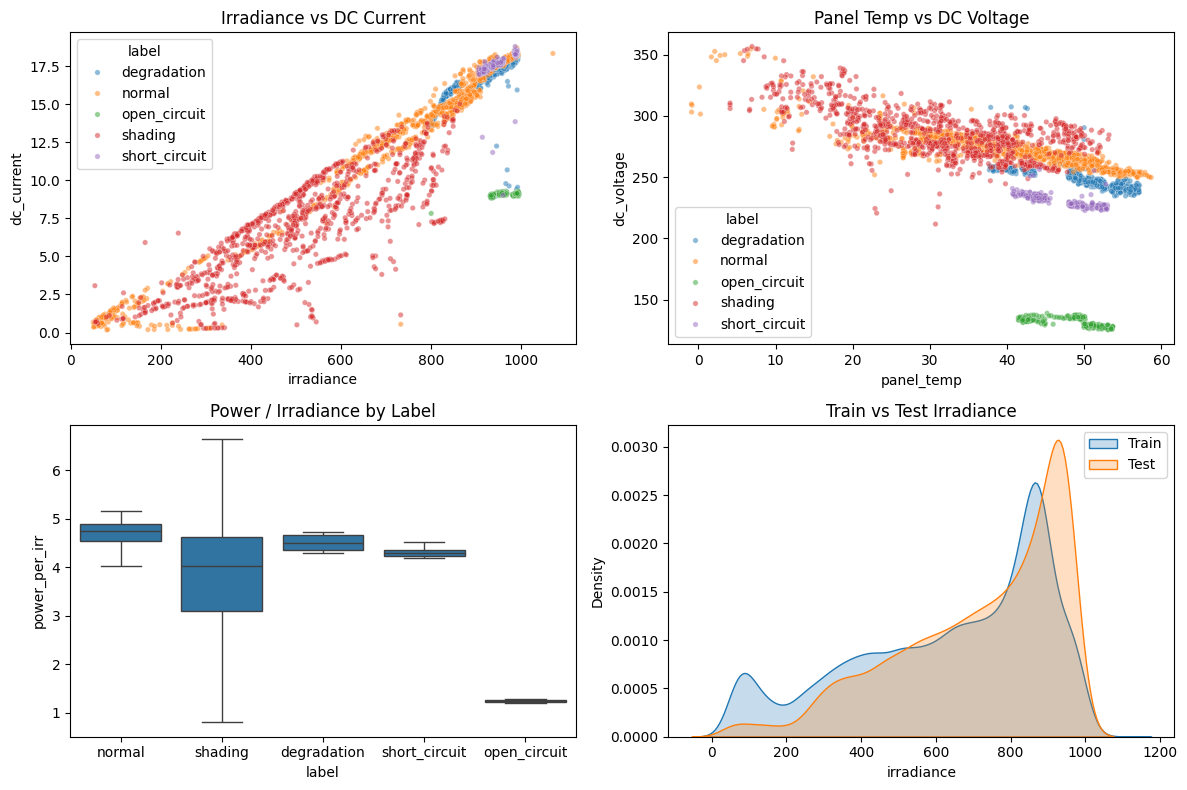

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sample_df = train.groupby('label', group_keys=False).apply(lambda x: x.sample(min(len(x), 1000), random_state=42))

# 1. Sunlight vs Current
sns.scatterplot(data=sample_df, x='irradiance', y='dc_current', hue='label', alpha=0.5, s=15, ax=axes[0, 0])
axes[0, 0].set_title('Irradiance vs DC Current')

# 2. Temperature vs Voltage
sns.scatterplot(data=sample_df, x='panel_temp', y='dc_voltage', hue='label', alpha=0.5, s=15, ax=axes[0, 1])
axes[0, 1].set_title('Panel Temp vs DC Voltage')

# 3. Efficiency Boxplot
sns.boxplot(data=train_fe, x='label', y='power_per_irr', showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title('Power / Irradiance by Label')

# 4. Train vs Test Irradiance Check
sns.kdeplot(train['irradiance'], label='Train', fill=True, ax=axes[1, 1])
sns.kdeplot(test['irradiance'], label='Test', fill=True, ax=axes[1, 1])
axes[1, 1].set_title('Train vs Test Irradiance')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('eda_charts.png', dpi=150)
plt.show()

In [ ]:
# Fit the normal physical baselines ONLY on normal training rows (zero data leakage)
normal_rows = train_fe[train_fe['label'] == 'normal']
i_slope, i_intercept = np.polyfit(normal_rows['irradiance'], normal_rows['dc_current'], 1)
v_slope, v_intercept = np.polyfit(normal_rows['panel_temp'], normal_rows['dc_voltage'], 1)

def add_residual_features(df):
    d = df.copy()
    # How much current is missing compared to a healthy panel at this sunlight?
    d['expected_current'] = i_slope * d['irradiance'] + i_intercept
    d['current_residual'] = d['dc_current'] - d['expected_current']
    d['current_ratio_expected'] = d['dc_current'] / (d['expected_current'] + 1e-5)

    # How much voltage is missing compared to a healthy panel at this temperature?
    d['expected_voltage'] = v_slope * d['panel_temp'] + v_intercept
    d['voltage_residual'] = d['dc_voltage'] - d['expected_voltage']
    d['voltage_ratio_expected'] = d['dc_voltage'] / (d['expected_voltage'] + 1e-5)
    return d

train_fe = add_residual_features(train_fe)
test_fe = add_residual_features(test_fe)

feature_cols = [c for c in test_fe.columns if c != 'id']
print(f"Ready! Total features: {len(feature_cols)}")

Ready! Total features: 23


In [ ]:
print(feature_cols)

['dc_voltage', 'dc_current', 'irradiance', 'panel_temp', 'dc_power', 'impedance', 'conductance', 'power_per_irr', 'current_per_irr', 'voltage_per_irr', 'temp_diff_25', 'temp_comp_voltage', 'temp_comp_power', 'temp_comp_eff', 'temp_per_irr', 'v_x_irr', 'i_x_temp', 'expected_current', 'current_residual', 'current_ratio_expected', 'expected_voltage', 'voltage_residual', 'voltage_ratio_expected']


In [ ]:
train_fe.head()

,id,day,dc_voltage,dc_current,irradiance,panel_temp,label,dc_power,impedance,conductance,...,temp_comp_eff,temp_per_irr,v_x_irr,i_x_temp,expected_current,current_residual,current_ratio_expected,expected_voltage,voltage_residual,voltage_ratio_expected
0,0,7,269.6065,10.6546,653.431,43.0411,normal,2872.549415,25.304211,0.039519,...,4.673689,0.065869,176169.244902,458.585704,11.343428,-0.688828,0.939274,269.003569,0.602931,1.002241
1,1,2,269.6190,15.2102,880.343,45.2181,normal,4100.958914,17.726185,0.056414,...,4.988006,0.051364,237357.199317,687.776345,15.750199,-0.539999,0.965714,266.613433,3.005567,1.011273
2,2,8,256.7280,17.8091,927.741,52.3153,normal,4572.094625,14.415544,0.069370,...,5.399355,0.056390,238177.091448,931.688409,16.670697,1.138403,1.068287,258.821390,-2.093390,0.991912
3,3,10,261.8030,6.0984,361.347,34.1854,shading,1596.579415,42.929714,0.023294,...,4.560458,0.094605,94601.728641,208.476243,5.670976,0.427424,1.075369,278.726276,-16.923276,0.939283
4,4,7,263.6355,14.8152,858.214,49.1793,normal,3905.812660,17.794922,0.056196,...,4.936242,0.057304,226255.676997,728.601165,15.320440,-0.505240,0.967021,262.264416,1.371084,1.005228


In [ ]:
test_fe.head()

,id,dc_voltage,dc_current,irradiance,panel_temp,dc_power,impedance,conductance,power_per_irr,current_per_irr,...,temp_comp_eff,temp_per_irr,v_x_irr,i_x_temp,expected_current,current_residual,current_ratio_expected,expected_voltage,voltage_residual,voltage_ratio_expected
0,102668,281.8425,11.5551,651.831,29.4147,3256.718272,24.391157,0.040998,4.996262,0.017727,...,5.073461,0.045126,183713.678618,339.889800,11.312355,0.242745,1.021458,283.964045,-2.121545,0.992529
1,100729,231.2920,17.0750,909.271,45.0962,3949.310900,13.545644,0.073824,4.343382,0.018779,...,4.648881,0.049596,210307.108132,770.017615,16.311999,0.763001,1.046775,266.747267,-35.455267,0.867083
2,104683,271.1050,17.7722,962.141,41.9921,4818.132281,15.254434,0.065555,5.007719,0.018472,...,5.305540,0.043644,260841.235805,746.292000,17.338767,0.433433,1.024997,270.155270,0.949730,1.003515
3,105575,273.1645,17.6047,954.496,40.8317,4808.979073,15.516558,0.064447,5.038239,0.018444,...,5.317413,0.042778,260734.422592,718.829829,17.190296,0.414404,1.024106,271.429278,1.735222,1.006393
4,101797,297.0275,6.9032,611.492,36.2988,2050.440238,43.027447,0.023241,3.353176,0.011289,...,3.485780,0.059361,181629.940030,250.577876,10.528946,-3.625746,0.655640,276.405966,20.621534,1.074606


## Target Encoding and feature slicing

In [ ]:
le = LabelEncoder()
y = le.fit_transform(train_fe['label'])

X = train_fe[feature_cols]
X_test = test_fe[feature_cols]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros((len(train_fe), len(le.classes_)))
test_probs = np.zeros((len(test_fe), len(le.classes_)))

print("Classes:", list(le.classes_))
print("Train shape:", X.shape)
print("Test shape:", X_test.shape)

Classes: ['degradation', 'normal', 'open_circuit', 'shading', 'short_circuit']
Train shape: (44017, 23)
Test shape: (9617, 23)


##7. Train Model and Evaluation

In [ ]:
from sklearn.model_selection import cross_val_predict

model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42)


oof_preds = cross_val_predict(model, X, y, cv=skf)
print(f"Accuracy: {accuracy_score(y, oof_preds):.5f}")
print(f"Macro F1: {f1_score(y, oof_preds, average='macro'):.5f}\n")
print(classification_report(y, oof_preds, target_names=le.classes_))

# 2. Train on full data & predict on test
model.fit(X, y)
test_preds = model.predict(X_test)

Accuracy: 0.99012
Macro F1: 0.99021

               precision    recall  f1-score   support

  degradation       0.99      0.99      0.99       691
       normal       0.99      0.99      0.99     26587
 open_circuit       0.99      1.00      1.00       242
      shading       0.99      0.99      0.99     16251
short_circuit       0.99      0.98      0.99       246

     accuracy                           0.99     44017
    macro avg       0.99      0.99      0.99     44017
 weighted avg       0.99      0.99      0.99     44017



##8. Save submission #1:

In [ ]:
submission = pd.DataFrame({
    'id': test_fe['id'],
    'label': le.inverse_transform(test_preds)
})

submission.to_csv('submission_1.csv', index=False)
print("Saved submission_1.csv! Rows:", len(submission))
print("\nPredicted counts:\n", submission['label'].value_counts())

Saved submission_1.csv! Rows: 9617

Predicted counts:
 label
normal           5658
shading          2995
open_circuit      360
degradation       316
short_circuit     288
Name: count, dtype: int64


## 8. switch to GroupKFold

In [ ]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)
oof_group = cross_val_predict(model, X, y, cv=gkf, groups=train['day'])

print(f"Unseen-Day GroupKFold Accuracy: {accuracy_score(y, oof_group):.5f}")
print(f"Unseen-Day GroupKFold Macro F1: {f1_score(y, oof_group, average='macro'):.5f}\n")
print(classification_report(y, oof_group, target_names=le.classes_, digits=4))

Unseen-Day GroupKFold Accuracy: 0.92664
Unseen-Day GroupKFold Macro F1: 0.73418

               precision    recall  f1-score   support

  degradation     0.6751    0.4240    0.5209       691
       normal     0.9442    0.9418    0.9430     26587
 open_circuit     0.9478    0.9752    0.9613       242
      shading     0.9093    0.9326    0.9208     16251
short_circuit     0.4324    0.2602    0.3249       246

     accuracy                         0.9266     44017
    macro avg     0.7818    0.7068    0.7342     44017
 weighted avg     0.9243    0.9266    0.9248     44017



In [ ]:
# 1. Keep only scale-invariant / day-independent physics features
drop_day_leaky = ['dc_voltage', 'panel_temp', 'expected_voltage', 'expected_current', 'temp_diff_25']
invariant_cols = [c for c in feature_cols if c not in drop_day_leaky]

X_inv = train_fe[invariant_cols]
X_test_inv = test_fe[invariant_cols]

# 2. Train balanced model that prioritizes rare faults
model_v2 = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,        # shallower trees prevent memorizing single days
    min_samples_leaf=30,
    class_weight='balanced',  # boosts recall on rare faults (short_circuit, degradation)
    random_state=42
)

oof_v2 = cross_val_predict(model_v2, X_inv, y, cv=gkf, groups=train['day'])
print(f"New Unseen-Day Accuracy: {accuracy_score(y, oof_v2):.5f}")
print(f"New Unseen-Day Macro F1: {f1_score(y, oof_v2, average='macro'):.5f}\n")
print(classification_report(y, oof_v2, target_names=le.classes_, digits=4))

New Unseen-Day Accuracy: 0.92880
New Unseen-Day Macro F1: 0.84342

               precision    recall  f1-score   support

  degradation     0.6624    0.5224    0.5841       691
       normal     0.9507    0.9343    0.9424     26587
 open_circuit     0.9887    0.7231    0.8353       242
      shading     0.9035    0.9393    0.9211     16251
short_circuit     0.8926    0.9797    0.9341       246

     accuracy                         0.9288     44017
    macro avg     0.8796    0.8198    0.8434     44017
 weighted avg     0.9286    0.9288    0.9283     44017



##Add is_low_voltage & Build the 2-Model Ensemble

In [ ]:
from sklearn.ensemble import VotingClassifier

train_fe['is_low_voltage'] = (train_fe['dc_voltage'] < 180).astype(int)
test_fe['is_low_voltage'] = (test_fe['dc_voltage'] < 180).astype(int)

cols_v3 = invariant_cols + ['is_low_voltage']
X_v3 = train_fe[cols_v3]
X_test_v3 = test_fe[cols_v3]

hgb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
    min_samples_leaf=30, class_weight='balanced', random_state=42
)
et = ExtraTreesClassifier(
    n_estimators=200, max_depth=16, min_samples_leaf=5,
    class_weight='balanced', n_jobs=-1, random_state=42
)

ensemble = VotingClassifier([('hgb', hgb), ('et', et)], voting='soft')
print("Ensemble ready with", len(cols_v3), "features!")

Ensemble ready with 19 features!


## Validate essemble on unseen data

In [ ]:
oof_v3 = cross_val_predict(ensemble, X_v3, y, cv=gkf, groups=train['day'])

print(f"Ensemble Unseen-Day Accuracy: {accuracy_score(y, oof_v3):.5f}")
print(f"Ensemble Unseen-Day Macro F1: {f1_score(y, oof_v3, average='macro'):.5f}\n")
print(classification_report(y, oof_v3, target_names=le.classes_, digits=4))

Ensemble Unseen-Day Accuracy: 0.93559
Ensemble Unseen-Day Macro F1: 0.89614

               precision    recall  f1-score   support

  degradation     0.8132    0.5355    0.6457       691
       normal     0.9519    0.9417    0.9468     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9122    0.9410    0.9264     16251
short_circuit     0.9526    0.9797    0.9659       246

     accuracy                         0.9356     44017
    macro avg     0.9243    0.8796    0.8961     44017
 weighted avg     0.9353    0.9356    0.9349     44017



In [ ]:
## saving Submission_2.csv

In [ ]:
ensemble.fit(X_v3, y)

sub2 = pd.DataFrame({
    'id': test_fe['id'],
    'label': le.inverse_transform(ensemble.predict(X_test_v3))
})

sub2.to_csv('submission_2.csv', index=False)
print("Saved submission_2.csv! Rows:", len(sub2))
print("\nPredicted counts:\n", sub2['label'].value_counts())

Saved submission_2.csv! Rows: 9617

Predicted counts:
 label
normal           5577
shading          2967
short_circuit     366
open_circuit      360
degradation       347
Name: count, dtype: int64


##Get Unseen-Day Out-of-Fold Probabilities & Tune degradation Multiplier

In [ ]:
# 1. Get out-of-fold probabilities on unseen days
oof_probs = cross_val_predict(ensemble, X_v3, y, cv=gkf, groups=train['day'], method='predict_proba')

# 2. Find best probability multiplier for class 0 ('degradation')
best_mult, best_f1 = 1.0, f1_score(y, oof_probs.argmax(axis=1), average='macro')

for mult in np.arange(1.0, 3.1, 0.2):
    adj_probs = oof_probs.copy()
    adj_probs[:, 0] *= mult
    score = f1_score(y, adj_probs.argmax(axis=1), average='macro')
    if score > best_f1:
        best_f1, best_mult = score, round(mult, 2)

print(f"Best degradation multiplier: {best_mult}x")
print(f"New Unseen-Day Macro F1:     {best_f1:.5f}\n")

final_oof = oof_probs.copy()
final_oof[:, 0] *= best_mult
print(classification_report(y, final_oof.argmax(axis=1), target_names=le.classes_, digits=4))

Best degradation multiplier: 1.0x
New Unseen-Day Macro F1:     0.89614

               precision    recall  f1-score   support

  degradation     0.8132    0.5355    0.6457       691
       normal     0.9519    0.9417    0.9468     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9122    0.9410    0.9264     16251
short_circuit     0.9526    0.9797    0.9659       246

     accuracy                         0.9356     44017
    macro avg     0.9243    0.8796    0.8961     44017
 weighted avg     0.9353    0.9356    0.9349     44017



##Test a 3-Model Ensemble (HGB + ExtraTrees + RandomForest)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200, max_depth=16, min_samples_leaf=5,
    class_weight='balanced', n_jobs=-1, random_state=42
)

ensemble_3 = VotingClassifier(
    [('hgb', hgb), ('et', et), ('rf', rf)],
    voting='soft'
)

oof_v4 = cross_val_predict(ensemble_3, X_v3, y, cv=gkf, groups=train['day'])
print(f"3-Model Unseen-Day Accuracy: {accuracy_score(y, oof_v4):.5f}")
print(f"3-Model Unseen-Day Macro F1: {f1_score(y, oof_v4, average='macro'):.5f}\n")
print(classification_report(y, oof_v4, target_names=le.classes_, digits=4))

3-Model Unseen-Day Accuracy: 0.93836
3-Model Unseen-Day Macro F1: 0.90395

               precision    recall  f1-score   support

  degradation     0.8109    0.5586    0.6615       691
       normal     0.9534    0.9445    0.9489     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9168    0.9428    0.9296     16251
short_circuit     0.9837    0.9837    0.9837       246

     accuracy                         0.9384     44017
    macro avg     0.9313    0.8859    0.9039     44017
 weighted avg     0.9381    0.9384    0.9378     44017



## Fit Final 3-Model Ensemble & Save submission_3.csv

In [ ]:
ensemble_3.fit(X_v3, y)

sub3 = pd.DataFrame({
    'id': test_fe['id'],
    'label': le.inverse_transform(ensemble_3.predict(X_test_v3))
})

sub3.to_csv('submission_3.csv', index=False)
print("Saved submission_3.csv! Rows:", len(sub3))
print("\nPredicted counts:\n", sub3['label'].value_counts())

Saved submission_3.csv! Rows: 9617

Predicted counts:
 label
normal           5591
shading          2973
open_circuit      360
degradation       348
short_circuit     345
Name: count, dtype: int64


## Adding smooth physics interactions

In [ ]:
def add_v4_features(df):
    d = df.copy()
    eps = 1e-5
    # 1. Joint thermal-voltage drop (isolates degradation at high sun/heat)
    d['v_res_x_irr'] = d['voltage_residual'] * d['irradiance']
    d['v_res_per_temp'] = d['voltage_residual'] / (d['panel_temp'] + 25.0)
    # 2. Normalized fill-factor proxy (ratio of actual efficiency to expected voltage)
    d['eff_to_v_ratio'] = d['power_per_irr'] / (d['voltage_ratio_expected'] + eps)
    return d

train_fe = add_v4_features(train_fe)
test_fe = add_v4_features(test_fe)

cols_v4 = cols_v3 + ['v_res_x_irr', 'v_res_per_temp', 'eff_to_v_ratio']
X_v4 = train_fe[cols_v4]
X_test_v4 = test_fe[cols_v4]

print("Ready! Total day-invariant features:", len(cols_v4))

Ready! Total day-invariant features: 22


##Build & Validate HGB + ExtraTrees + MLP Neural Net Ensemble

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=80, early_stopping=True, random_state=42)
)

ensemble_4 = VotingClassifier(
    [('hgb', hgb), ('et', et), ('mlp', mlp)],
    voting='soft',
    weights=[2, 2, 1]  # keeps strong HGB+ET core while smoothing boundaries with MLP
)

oof_v4 = cross_val_predict(ensemble_4, X_v4, y, cv=gkf, groups=train['day'])
print(f"V4 Unseen-Day Accuracy: {accuracy_score(y, oof_v4):.5f}")
print(f"V4 Unseen-Day Macro F1: {f1_score(y, oof_v4, average='macro'):.5f}\n")
print(classification_report(y, oof_v4, target_names=le.classes_, digits=4))

V4 Unseen-Day Accuracy: 0.94073
V4 Unseen-Day Macro F1: 0.91249

               precision    recall  f1-score   support

  degradation     0.7674    0.6397    0.6977       691
       normal     0.9547    0.9473    0.9510     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9232    0.9411    0.9320     16251
short_circuit     0.9838    0.9878    0.9858       246

     accuracy                         0.9407     44017
    macro avg     0.9242    0.9032    0.9125     44017
 weighted avg     0.9405    0.9407    0.9405     44017



##Fit Final V4 Ensemble & Save

In [ ]:
ensemble_4.fit(X_v4, y)

sub4 = pd.DataFrame({
    'id': test_fe['id'],
    'label': le.inverse_transform(ensemble_4.predict(X_test_v4))
})

sub4.to_csv('submission_4.csv', index=False)
print("Saved submission_4.csv! Rows:", len(sub4))
print("\nPredicted counts:\n", sub4['label'].value_counts())

Saved submission_4.csv! Rows: 9617

Predicted counts:
 label
normal           5583
shading          2966
short_circuit     367
open_circuit      360
degradation       341
Name: count, dtype: int64


##. Train a Class-Balanced Neural Network (MLP_bal) + 4-Model Ensemblem

In [ ]:
from sklearn.preprocessing import QuantileTransformer

mlp_quant = make_pipeline(
    QuantileTransformer(n_quantiles=500, output_distribution='normal', random_state=42),
    MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        alpha=1e-3,
        max_iter=100,
        early_stopping=True,
        random_state=101
    )
)

ensemble_5 = VotingClassifier(
    [('hgb', hgb), ('et', et), ('mlp1', mlp), ('mlp2', mlp_quant)],
    voting='soft',
    weights=[2, 2, 1, 2]
)

oof_v5 = cross_val_predict(ensemble_5, X_v4, y, cv=gkf, groups=train['day'])
print(f"V5 Unseen-Day Accuracy: {accuracy_score(y, oof_v5):.5f}")
print(f"V5 Unseen-Day Macro F1: {f1_score(y, oof_v5, average='macro'):.5f}\n")
print(classification_report(y, oof_v5, target_names=le.classes_, digits=4))

V5 Unseen-Day Accuracy: 0.93893
V5 Unseen-Day Macro F1: 0.90207

               precision    recall  f1-score   support

  degradation     0.7378    0.5904    0.6559       691
       normal     0.9527    0.9464    0.9495     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9225    0.9399    0.9311     16251
short_circuit     0.9681    0.9878    0.9779       246

     accuracy                         0.9389     44017
    macro avg     0.9146    0.8929    0.9021     44017
 weighted avg     0.9385    0.9389    0.9385     44017



##Multi-Seed StandardScaler MLP + V4 Ensemble (Zero Feature Distortion)

In [ ]:
mlp_b = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(96, 48), alpha=5e-4, max_iter=100, early_stopping=True, random_state=7)
)

ensemble_6 = VotingClassifier(
    [('hgb', hgb), ('et', et), ('mlp1', mlp), ('mlp2', mlp_b)],
    voting='soft',
    weights=[2, 2, 1, 1]
)

oof_v6 = cross_val_predict(ensemble_6, X_v4, y, cv=gkf, groups=train['day'])
print(f"V6 Unseen-Day Accuracy: {accuracy_score(y, oof_v6):.5f}")
print(f"V6 Unseen-Day Macro F1: {f1_score(y, oof_v6, average='macro'):.5f}\n")
print(classification_report(y, oof_v6, target_names=le.classes_, digits=4))

V6 Unseen-Day Accuracy: 0.94407
V6 Unseen-Day Macro F1: 0.92525

               precision    recall  f1-score   support

  degradation     0.7955    0.7207    0.7563       691
       normal     0.9576    0.9500    0.9538     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9268    0.9423    0.9345     16251
short_circuit     0.9838    0.9878    0.9858       246

     accuracy                         0.9441     44017
    macro avg     0.9311    0.9202    0.9253     44017
 weighted avg     0.9440    0.9441    0.9440     44017



## fit final V6 essemble and save sumbissions

In [ ]:
ensemble_6.fit(X_v4, y)

sub5 = pd.DataFrame({
    'id': test_fe['id'],
    'label': le.inverse_transform(ensemble_6.predict(X_test_v4))
})

sub5.to_csv('submission_5.csv', index=False)
print("Saved submission_5.csv! Rows:", len(sub5))
print("\nPredicted counts:\n", sub5['label'].value_counts())

Saved submission_5.csv! Rows: 9617

Predicted counts:
 label
normal           5575
shading          2968
short_circuit     367
open_circuit      360
degradation       347
Name: count, dtype: int64


In [ ]:
mlp_c = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(128, 64), alpha=5e-4, max_iter=100, early_stopping=True, random_state=21)
)

ensemble_8 = VotingClassifier(
    [('hgb', hgb), ('et', et), ('mlp1', mlp), ('mlp2', mlp_b), ('mlp3', mlp_c)],
    voting='soft',
    weights=[2, 2, 1, 1, 1]
)

oof_v8 = cross_val_predict(ensemble_8, X_v4, y, cv=gkf, groups=train['day'])
print(f"V8 Unseen-Day Accuracy: {accuracy_score(y, oof_v8):.5f}")
print(f"V8 Unseen-Day Macro F1: {f1_score(y, oof_v8, average='macro'):.5f}\n")
print(classification_report(y, oof_v8, target_names=le.classes_, digits=4))

V8 Unseen-Day Accuracy: 0.94327
V8 Unseen-Day Macro F1: 0.91738

               precision    recall  f1-score   support

  degradation     0.7717    0.6700    0.7173       691
       normal     0.9563    0.9501    0.9532     26587
 open_circuit     0.9918    1.0000    0.9959       242
      shading     0.9274    0.9423    0.9348     16251
short_circuit     0.9838    0.9878    0.9858       246

     accuracy                         0.9433     44017
    macro avg     0.9262    0.9100    0.9174     44017
 weighted avg     0.9431    0.9433    0.9431     44017



In [34]:
ensemble_8.fit(X_v4, y)

sub6 = pd.DataFrame({
    'id': test_fe['id'],
    'label': le.inverse_transform(ensemble_8.predict(X_test_v4))
})

sub6.to_csv('submission_6.csv', index=False)
print("Saved submission_6.csv! Rows:", len(sub6))
print("\nPredicted counts:\n", sub6['label'].value_counts())

Saved submission_6.csv! Rows: 9617

Predicted counts:
 label
normal           5590
shading          2952
short_circuit     367
open_circuit      360
degradation       348
Name: count, dtype: int64


# the V6 (submission_5.csv) performs best overall